# Supplementary Figure 11 — Distribution of tissue-specificity (τ) across transcription factor groups

Reproduces the three-panel histogram figure (related to Figure 3):

- **A)** Core essential TS2 transcription factors
- **B)** Transcription factors with no known motif (Codebook)
- **C)** Low tau Zinc finger transcription factors

Each panel reports mean, median and standard deviation; the dashed vertical line marks the mean and the dotted line marks the median.

## Input

Three CSVs in DATA_DIR, one row per gene (gene symbol in the unnamed first column, τ in the `tau` column):

| file | panel |
|---|---|
| `49_core_essential_TS2_TF.csv` | A |
| `TFs_unknown_motif_codebook.csv` | B |
| `low_tau_zinc_finger_TFs.csv` | C |

Outputs are written as PNG (300 dpi) and PDF.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.grid": True,
    "grid.color": "#dddddd",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
})

DATA_DIR = '/oak/stanford/groups/quake/jonesbob/TF_TS_Analysis_Final_Manuscript/ClaudeFiles/'
OUT_DIR = '/oak/stanford/groups/quake/jonesbob/TF_TS_Analysis_Final_Manuscript/'

PANELS = [
    # (panel letter, file, title, bar color)
    ("A", "49_core_essential_TS2_TF.csv",   "Core Essential TS2_TF",   "#3dbf7f"),
    ("B", "TFs_unknown_motif_codebook.csv", "TFs with No Known Motif", "#e8615a"),
    ("C", "low_tau_zinc_finger_TFs.csv",        "Low τ Zinc Finger TFs",   "#4a90e2"),
]

## Load data

In [8]:
def load_tau(fname):
    df = pd.read_csv(DATA_DIR + fname, index_col=0)
    df.index.name = "gene"
    return df

data = {p: load_tau(f) for p, f, _, _ in PANELS}

pd.DataFrame({
    p: data[p]["tau"].agg(["count", "mean", "median", "std"]) for p in data
}).T.round(3)

,count,mean,median,std
A,49.0,0.755,0.770,0.142
B,214.0,0.797,0.809,0.140
C,418.0,0.746,0.760,0.079


## Plot

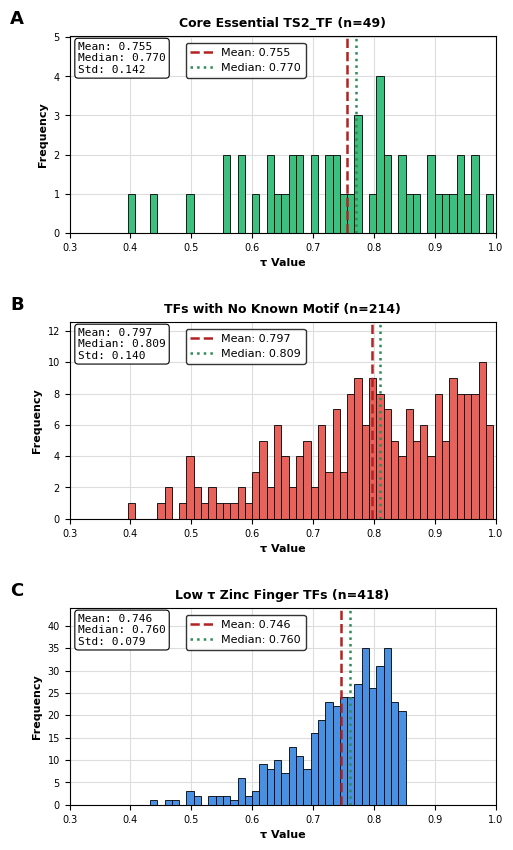

In [15]:
BINS = np.arange(0.30, 1.0001, 0.012)

def plot_tau_hist(ax, tau, title, color, panel):
    tau = np.asarray(tau, dtype=float)
    n, mean, median, std = len(tau), tau.mean(), np.median(tau), tau.std(ddof=1)

    ax.hist(tau, bins=BINS, color=color, edgecolor="black", linewidth=0.6)
    ax.axvline(mean,   color="#b22222", linestyle="--", linewidth=1.8, label=f"Mean: {mean:.3f}")
    ax.axvline(median, color="#2e8b57", linestyle=":",  linewidth=1.8, label=f"Median: {median:.3f}")

    ax.text(0.02, 0.97, f"Mean: {mean:.3f}\nMedian: {median:.3f}\nStd: {std:.3f}",
            transform=ax.transAxes, va="top", ha="left", fontsize=8, family="monospace",
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="black", linewidth=0.8))

    # Legend sits just right of the stats box; add headroom so neither box overlaps bars
    ax.legend(loc="upper left", bbox_to_anchor=(0.26, 0.99), fontsize=8, frameon=True, edgecolor="black")
    ax.set_ylim(0, ax.get_ylim()[1] * 1.20)
    ax.set_xlim(0.3, 1.0)
    ax.set_xlabel("τ Value", fontweight="bold", fontsize=8)
    ax.set_ylabel("Frequency", fontweight="bold", fontsize=8)
    ax.set_title(f"{title} (n={n})", fontweight="bold", fontsize=9)
    ax.tick_params(labelsize=7)
    ax.text(-0.14, 1.06, panel, transform=ax.transAxes, fontsize=13, fontweight="bold")

fig, axes = plt.subplots(3, 1, figsize=(5.2, 8.6))
for ax, (p, _, title, color) in zip(axes, PANELS):
    plot_tau_hist(ax, data[p]["tau"], title, color, p)

fig.tight_layout(h_pad=2.0)
fig.savefig(f"{OUT_DIR}/supp_fig_11_tau_distributions.png", dpi=300, bbox_inches="tight")
fig.savefig(f"{OUT_DIR}/supp_fig_11_tau_distributions.pdf", bbox_inches="tight")
plt.show()

## Figure legend

**Supplementary Figure 11. Distribution of tissue-specificity (τ) across transcription factor groups, related to Figure 3.** Histograms show τ values for **A)** core essential TS2 transcription factors, **B)** transcription factors with no known motif, and **C)** low tau zinc finger transcription factors. Mean, median, and standard deviation are reported in each panel; dashed vertical lines indicate the mean and dotted vertical lines indicate the median.